# ECMI 2026 Student Competition: exploratory analysis

Data: Savic, Lukic et al. (2021), *Deep Learning Anomaly Detection for Cellular IoT with Applications in Smart Logistics*, [zenodo 4686782](https://zenodo.org/records/4686782). The original files are in `original/`.

Each row is one GNSS interval (~10 s in both months; in March the time stamps are cut to whole minutes, so 5–6 rows share one stamp). GPS fields are instantaneous; the IMU fields are the RMS of the ~15 ms acceleration (m/s²) and magnetic field (µT) samples in that interval. `training.csv` has no labels, `test.csv` comes with `anomalies.timestamps`.

`GPS_speed` is converted from knots to m/s on loading (the unit is not stated in the dataset, it is inferred from the distance between consecutive fixes). This notebook only looks at the data; there is no model yet.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
DATA = Path("original")
G = 9.81
TOL = pd.Timedelta("60s")      # verify.py accepts a hit within about one minute

def parse_ts(s):
    # The files mix three formats; 'DD-MM-YY' dates were also re-saved as '20DD-03-21'
    s = s.strip()
    if m := re.fullmatch(r"(\d\d)-(\d\d)-(\d\d) (\d{1,2}:\d\d(?::\d\d)?)", s):
        return pd.Timestamp(f"20{m[3]}-{m[2]}-{m[1]} {m[4]}")
    if m := re.fullmatch(r"20(\d\d)-03-21 (.*)", s):
        return pd.Timestamp(f"2021-03-{m[1]} {m[2]}")
    return pd.Timestamp(s)

def load(name, split):
    d = pd.read_csv(DATA / name)
    d["t"] = d.timestamp.map(parse_ts)
    d["split"] = split
    d["GPS_speed"] = d.GPS_speed * 0.5144      # the file does not give a unit; the change of position says knots (~2x m/s), so convert to m/s
    d["acc"] = np.sqrt(d.ACC_x_RMS**2 + d.ACC_y_RMS**2 + d.ACC_z_RMS**2)   # = RMS of |a|, rotation invariant
    d["mag"] = np.sqrt(d.MAG_x_RMS**2 + d.MAG_y_RMS**2 + d.MAG_z_RMS**2)   # = RMS of |B|
    d["no_fix"] = (d.GPS_lat == 0) & (d.GPS_lon == 0)
    d["dropped_by_paper"] = d.no_fix | (d.GPS_alt < 0) | (d.MAG_samples > 10000)
    dt = d.t.diff().dt.total_seconds()
    d["dt"] = dt
    d["session"] = ((dt > 300) | (dt < 0)).cumsum()          # gap > 5 min or time goes backwards
    d["regime"] = np.where(d.t < "2021-03-01", "Jan (10 s, GPS speed ok)", "Mar (1-min stamps, no GPS speed)")
    return d

tr = load("training.csv", "train")
te = load("test.csv", "test")
anom = pd.Series([parse_ts(l) for l in (DATA / "anomalies.timestamps").read_text().splitlines() if l.strip()])
te["near_anom"] = te.t.apply(lambda x: (abs(anom - x) <= TOL).any())
te["anom_id"] = te.t.apply(lambda x: int(np.argmin(abs(anom - x))) if (abs(anom - x) <= TOL).any() else -1)
tr["near_anom"] = False
df = pd.concat([tr, te], ignore_index=True)
df["label"] = np.where(df.split == "train", "train", np.where(df.near_anom, "test, ≤1 min from anomaly", "test, normal"))
PAL = {"train": "#4C72B0", "test, normal": "#55A868", "test, ≤1 min from anomaly": "#C44E52"}
IMU = ["ACC_x_RMS", "ACC_y_RMS", "ACC_z_RMS", "MAG_x_RMS", "MAG_y_RMS", "MAG_z_RMS"]
print(f"train {tr.shape}, test {te.shape}, anomaly timestamps {len(anom)}")

train (12678, 24), test (1571, 25), anomaly timestamps 39


## 1. What is in the files

In [2]:
def overview(d):
    return pd.Series({
        "rows": len(d),
        "sessions": d.session.nunique(),
        "first": d.t.min(), "last": d.t.max(),
        "time-ordered in file": d.t.is_monotonic_increasing,
        "rows January": (d.t < "2021-03-01").sum(),
        "rows March": (d.t >= "2021-03-01").sum(),
        "no GPS fix (lat=lon=0)": d.no_fix.sum(),
        "dropped by the paper's loader": d.dropped_by_paper.sum(),
        "GPS speed > 1 m/s": (d.GPS_speed > 1).sum(),
    })
display(pd.DataFrame({"train": overview(tr), "test": overview(te)}))
display(tr.head(3)); display(tr[tr.t >= "2021-03-01"].head(3))
display(df.groupby("split")[["GPS_speed", "GPS_num_sats", "acc", "mag"] + IMU].describe().T.round(2))

,train,test
rows,12678,1571
sessions,84,21
first,2021-01-22 08:47:55,2021-01-21 14:36:54
last,2021-03-15 08:00:00,2021-03-23 13:44:00
time-ordered in file,False,True
rows January,1470,318
rows March,11208,1253
no GPS fix (lat=lon=0),924,190
dropped by the paper's loader,935,191
GPS speed > 1 m/s,1203,211


,timestamp,GPS_lat,GPS_lon,GPS_alt,GPS_speed,GPS_num_sats,ACC_x_RMS,ACC_y_RMS,ACC_z_RMS,ACC_samples,...,t,split,acc,mag,no_fix,dropped_by_paper,dt,session,regime,near_anom
0,2021-01-22 08:47:55,45.23717,19.83952,98.0,0.041666,5,1.69930,2.32812,9.83933,109,...,2021-01-22 08:47:55,train,10.252813,104.041432,False,False,NaN,0,"Jan (10 s, GPS speed ok)",False
1,2021-01-22 08:48:04,45.23714,19.83982,93.0,6.807055,5,1.22636,3.34401,9.46543,670,...,2021-01-22 08:48:04,train,10.113393,107.881245,False,False,9.0,0,"Jan (10 s, GPS speed ok)",False
2,2021-01-22 08:48:15,45.23747,19.84089,86.4,10.298288,6,1.87620,2.59185,9.47308,670,...,2021-01-22 08:48:15,train,9.998853,109.425286,False,False,11.0,0,"Jan (10 s, GPS speed ok)",False


,timestamp,GPS_lat,GPS_lon,GPS_alt,GPS_speed,GPS_num_sats,ACC_x_RMS,ACC_y_RMS,ACC_z_RMS,ACC_samples,...,t,split,acc,mag,no_fix,dropped_by_paper,dt,session,regime,near_anom
1470,10-03-21 12:21,45.24179,19.83471,98.0,0.0,10,0.48471,0.70242,9.65671,546,...,2021-03-10 12:21:00,train,9.694348,86.215113,False,False,3883400.0,13,"Mar (1-min stamps, no GPS speed)",False
1471,10-03-21 12:21,45.24178,19.83471,98.0,0.0,10,0.50837,0.71895,9.64576,546,...,2021-03-10 12:21:00,train,9.685867,86.303875,False,False,0.0,13,"Mar (1-min stamps, no GPS speed)",False
1472,10-03-21 12:21,45.24178,19.83471,98.0,0.0,10,0.50837,0.70242,9.66766,546,...,2021-03-10 12:21:00,train,9.706466,86.163551,False,False,0.0,13,"Mar (1-min stamps, no GPS speed)",False


split               test     train
GPS_speed count  1571.00  12678.00
          mean      0.79      0.97
          std       2.20      3.34
          min       0.00      0.00
          25%       0.00      0.00
...                  ...       ...
MAG_z_RMS min       1.37      0.60
          25%      12.92     21.55
          50%      25.69     30.44
          75%      37.93     54.57
          max      87.29    169.85

[80 rows x 2 columns]

## 2. When was the data recorded

Each bar is a session (gap > 5 min or the clock jumps back). Red ticks are the anomaly timestamps.

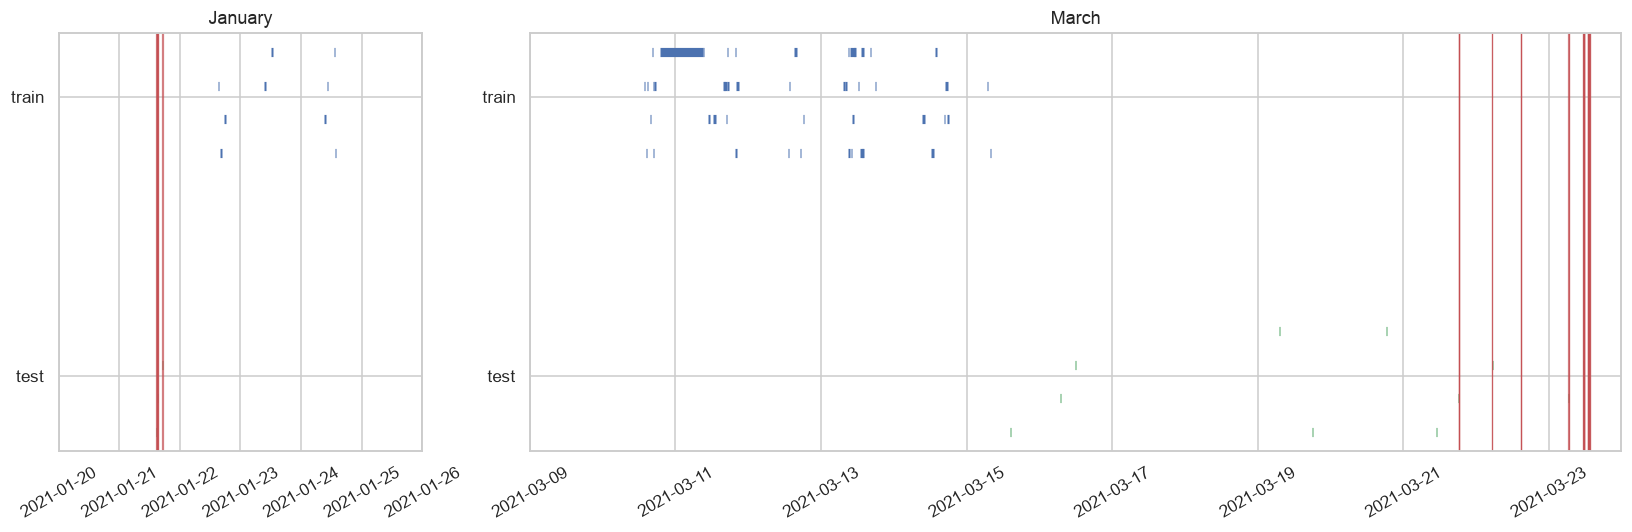

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 3]})
for ax, (lo, hi) in zip(axes, [("2021-01-20", "2021-01-26"), ("2021-03-09", "2021-03-24")]):
    for (split, s), g in df.groupby(["split", "session"]):
        if g.t.min() < pd.Timestamp(lo) or g.t.min() > pd.Timestamp(hi):
            continue
        y = 1 if split == "train" else 0
        y += (s % 4) * 0.12   # stagger overlapping sessions
        ax.plot([g.t.min(), g.t.max() + pd.Timedelta("1min")], [y, y], lw=6,
                color=PAL["train"] if split == "train" else PAL["test, normal"], solid_capstyle="butt")
    for a in anom[(anom > lo) & (anom < hi)]:
        ax.axvline(a, color=PAL["test, ≤1 min from anomaly"], lw=0.8, alpha=0.7)
    ax.set_xlim(pd.Timestamp(lo), pd.Timestamp(hi)); ax.set_yticks([0.2, 1.2], ["test", "train"])
    ax.tick_params(axis="x", rotation=30)
axes[0].set_title("January"); axes[1].set_title("March")
plt.tight_layout(); plt.show()

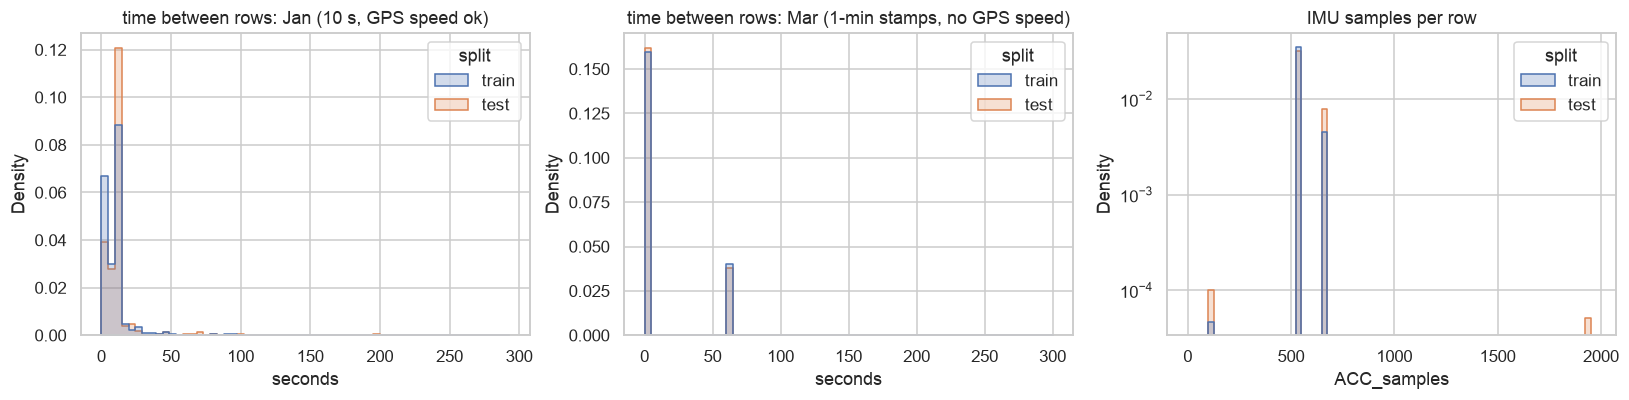

rows per test session:
                      start  rows  anomalies
session                                     
0       2021-01-21 14:36:54   117         31
1       2021-01-21 15:02:31   134         57
2       2021-01-21 16:55:39    67         26
4       2021-03-15 14:26:00   113          0
5       2021-03-16 06:56:00    90          0
6       2021-03-16 11:48:00    86          0
7       2021-03-19 06:59:00   140          0
8       2021-03-19 17:57:00    37          0
9       2021-03-20 10:45:00    16          0
10      2021-03-20 17:42:00    31          0
11      2021-03-20 18:12:00   121          0
12      2021-03-21 10:57:00    65          0
13      2021-03-21 18:11:00    86         48
14      2021-03-22 05:19:00    53         28
15      2021-03-22 14:44:00    24         19
16      2021-03-22 14:55:00    13         13
17      2021-03-23 06:32:00    30         30
18      2021-03-23 11:12:00   173        110
19      2021-03-23 12:54:00   160        103
20      2021-03-23 13:41:00    1

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (reg, g) in zip(axes[:2], df[df.dt.between(0, 300)].groupby("regime")):
    sns.histplot(g, x="dt", hue="split", bins=60, ax=ax, element="step", stat="density", common_norm=False)
    ax.set_title(f"time between rows: {reg}"); ax.set_xlabel("seconds")
sns.histplot(df, x="ACC_samples", hue="split", bins=np.arange(0, 2000, 25), ax=axes[2], element="step", stat="density", common_norm=False)
axes[2].set_title("IMU samples per row"); axes[2].set_yscale("log")
plt.tight_layout(); plt.show()
print("rows per test session:"); print(te.groupby("session").agg(start=("t", "min"), rows=("t", "size"), anomalies=("near_anom", "sum")).query("rows > 5").to_string())

Note: in March the timestamps are cut to whole minutes (about 5–6 rows share one stamp; 546 IMU samples × 15 ms ≈ 8 s per row) and `GPS_speed` is always 0, even though the position keeps changing. So March speed is missing, not "parked". It also means "±1 min from an anomaly" covers ~15 rows in March, which is why ~30 % of test rows get the red label.

## 3. Where: GPS track

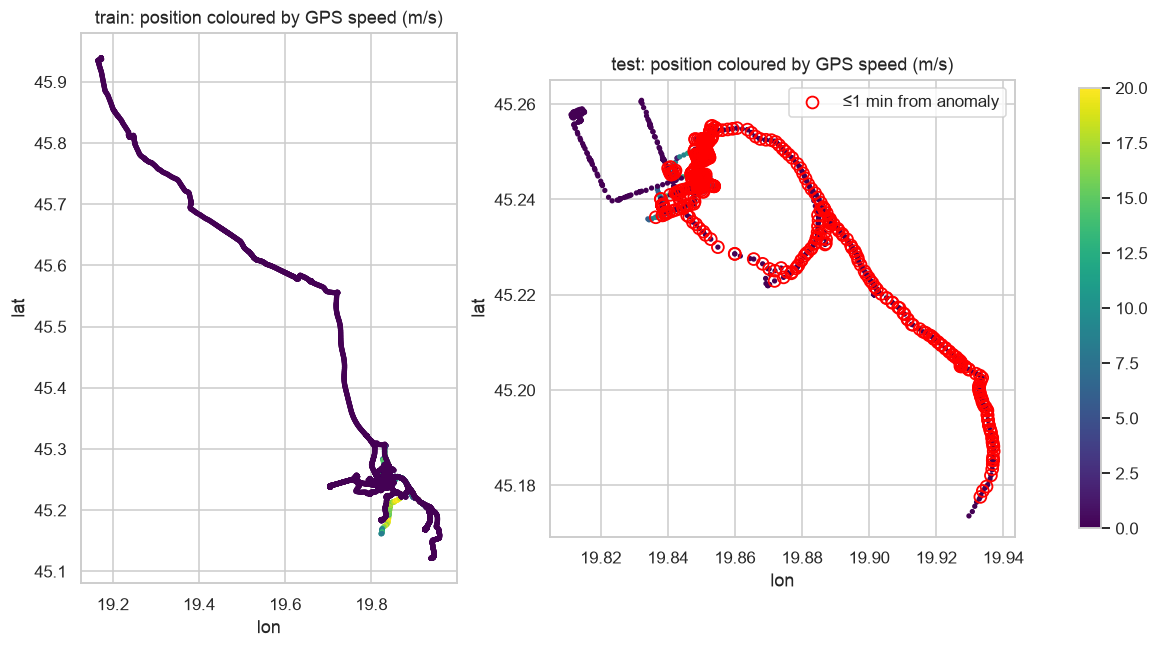

rows outside the Novi Sad area (lat > 45.3): 1423


In [5]:
gps = df[~df.no_fix & (df.GPS_lat > 44)]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, split in zip(axes, ["train", "test"]):
    g = gps[gps.split == split]
    sc = ax.scatter(g.GPS_lon, g.GPS_lat, c=g.GPS_speed, s=6, cmap="viridis", vmax=20)
    if split == "test":
        a = g[g.near_anom]
        ax.scatter(a.GPS_lon, a.GPS_lat, s=60, facecolors="none", edgecolors="red", lw=1.2, label="≤1 min from anomaly")
        ax.legend()
    ax.set_title(f"{split}: position coloured by GPS speed (m/s)"); ax.set_xlabel("lon"); ax.set_ylabel("lat")
    ax.set_aspect(1 / np.cos(np.radians(45.24)))
plt.colorbar(sc, ax=axes, shrink=0.8); plt.show()
print("rows outside the Novi Sad area (lat > 45.3):", (gps.GPS_lat > 45.3).sum())

## 4. Distributions of every column

Train vs test-normal vs test rows within a minute of an anomaly (densities, each group normalised separately).

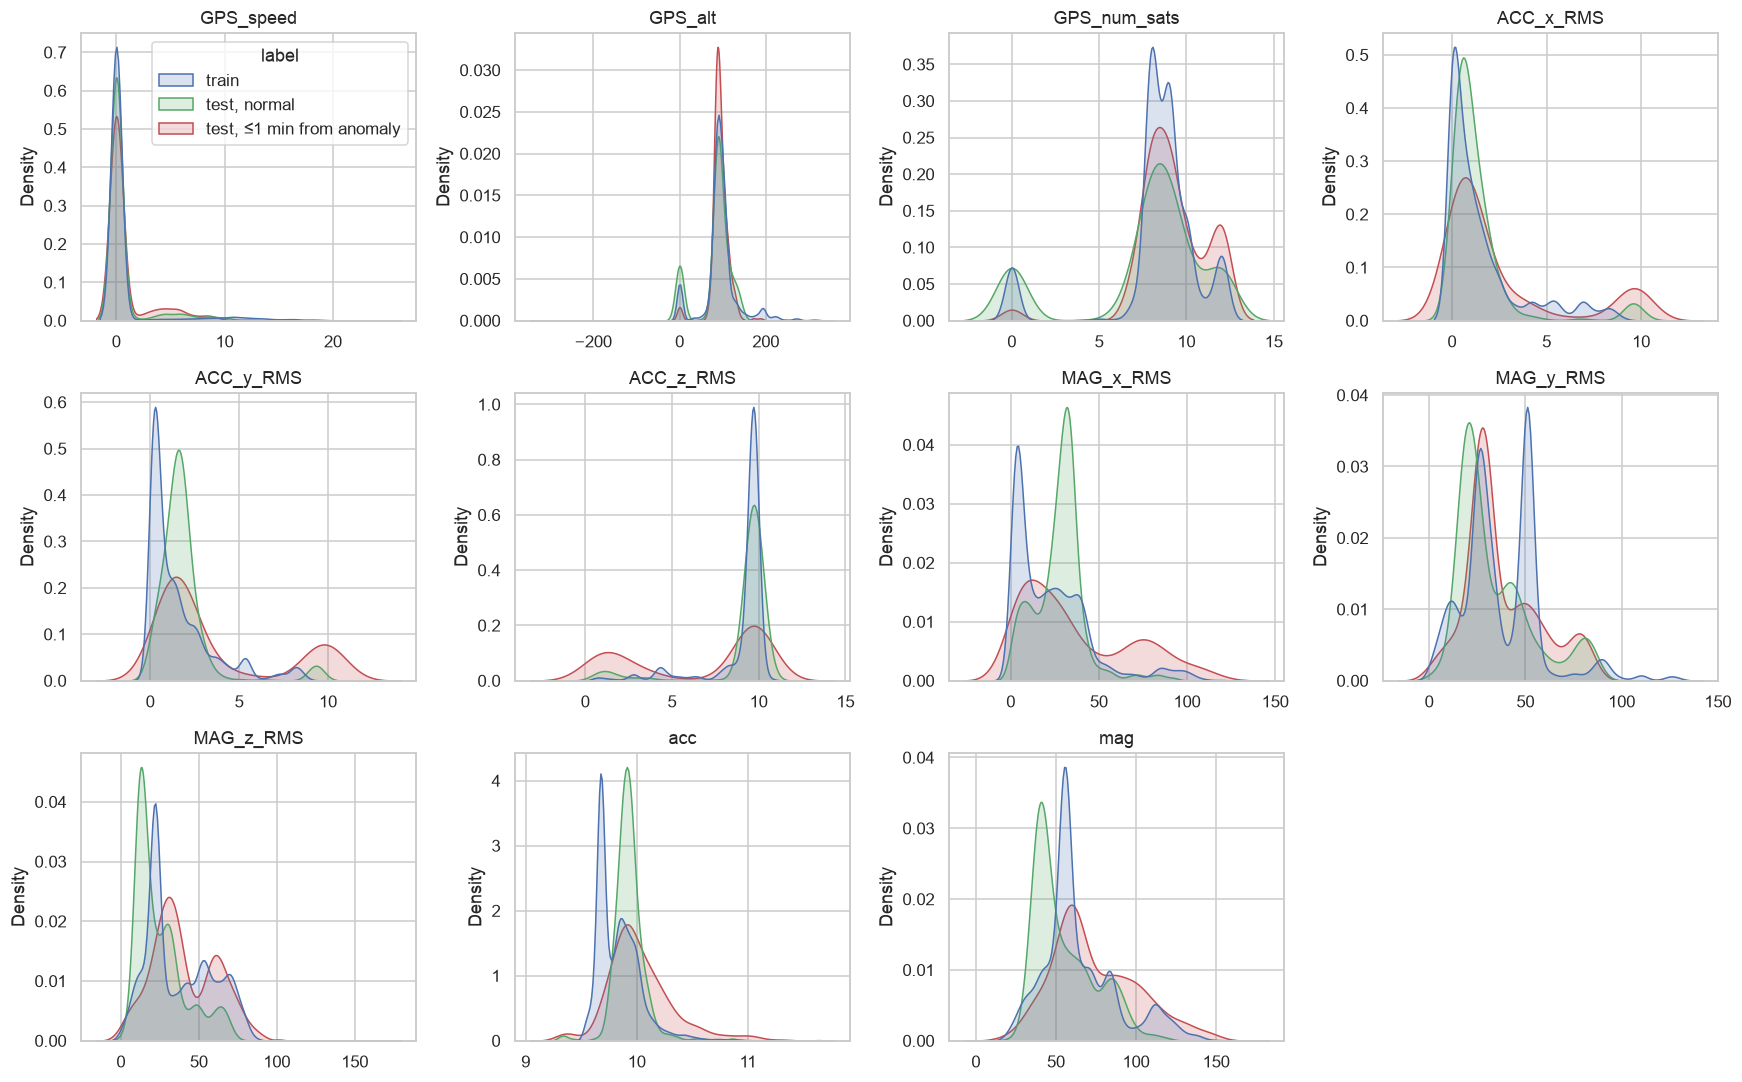

In [6]:
cols = ["GPS_speed", "GPS_alt", "GPS_num_sats"] + IMU + ["acc", "mag"]
fig, axes = plt.subplots(3, 4, figsize=(16, 10)); axes = axes.ravel()
for ax, c in zip(axes, cols):
    sns.kdeplot(df, x=c, hue="label", palette=PAL, common_norm=False, ax=ax, fill=True, alpha=0.2, warn_singular=False, legend=ax is axes[0])
    ax.set_title(c); ax.set_xlabel("")
axes[-1].axis("off")
plt.tight_layout(); plt.show()

## 5. Rotation-invariant magnitudes

`acc` = √(x²+y²+z²) of the per-axis RMS values, which is exactly the RMS of |a| over the interval, so it does not depend on how the box is oriented. Same for `mag`. A parked box should give `acc` ≈ g.

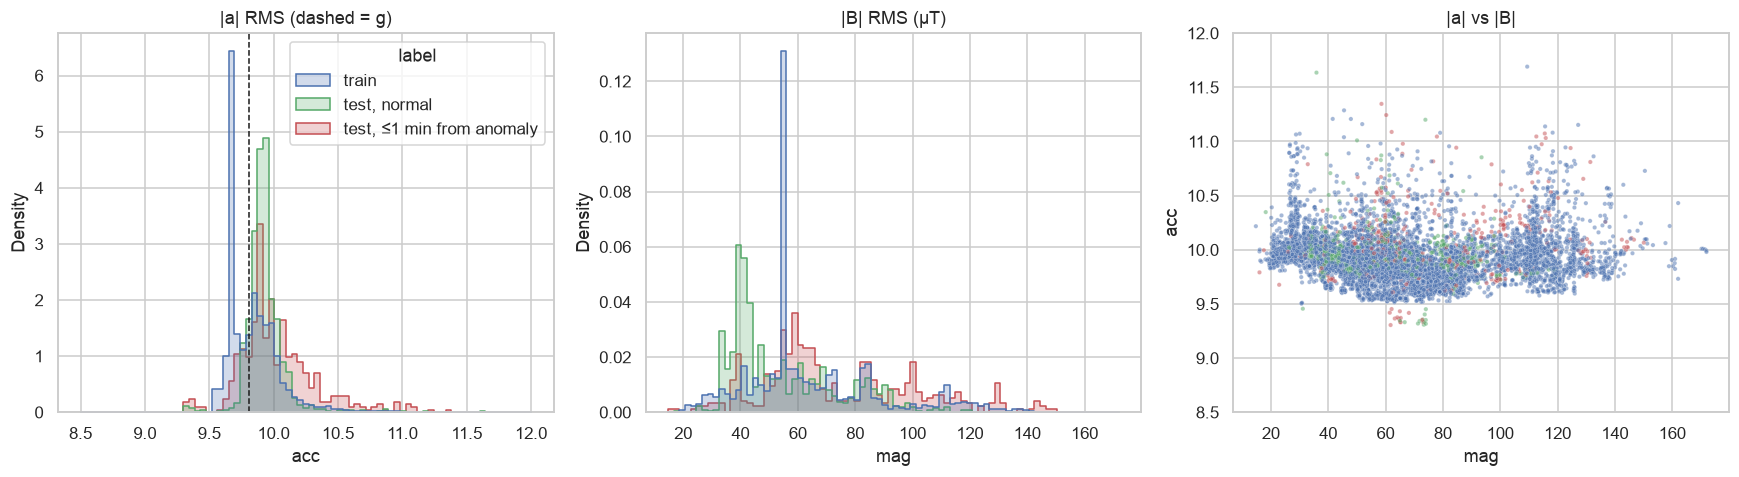

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(df, x="acc", hue="label", palette=PAL, bins=np.linspace(8.5, 12, 80), stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].axvline(G, color="k", ls="--", lw=1); axes[0].set_title("|a| RMS (dashed = g)")
sns.histplot(df, x="mag", hue="label", palette=PAL, bins=80, stat="density", common_norm=False, element="step", ax=axes[1], legend=False)
axes[1].set_title("|B| RMS (µT)")
sns.scatterplot(df.sample(frac=1, random_state=0), x="mag", y="acc", hue="label", palette=PAL, s=8, alpha=0.5, ax=axes[2], legend=False)
axes[2].set_ylim(8.5, 12); axes[2].set_title("|a| vs |B|")
plt.tight_layout(); plt.show()

## 6. The field level depends on the session

Box plots per session (only sessions with ≥ 30 rows). If the spread *inside* a session is much smaller than *between* sessions, a single global threshold on |B| cannot work.

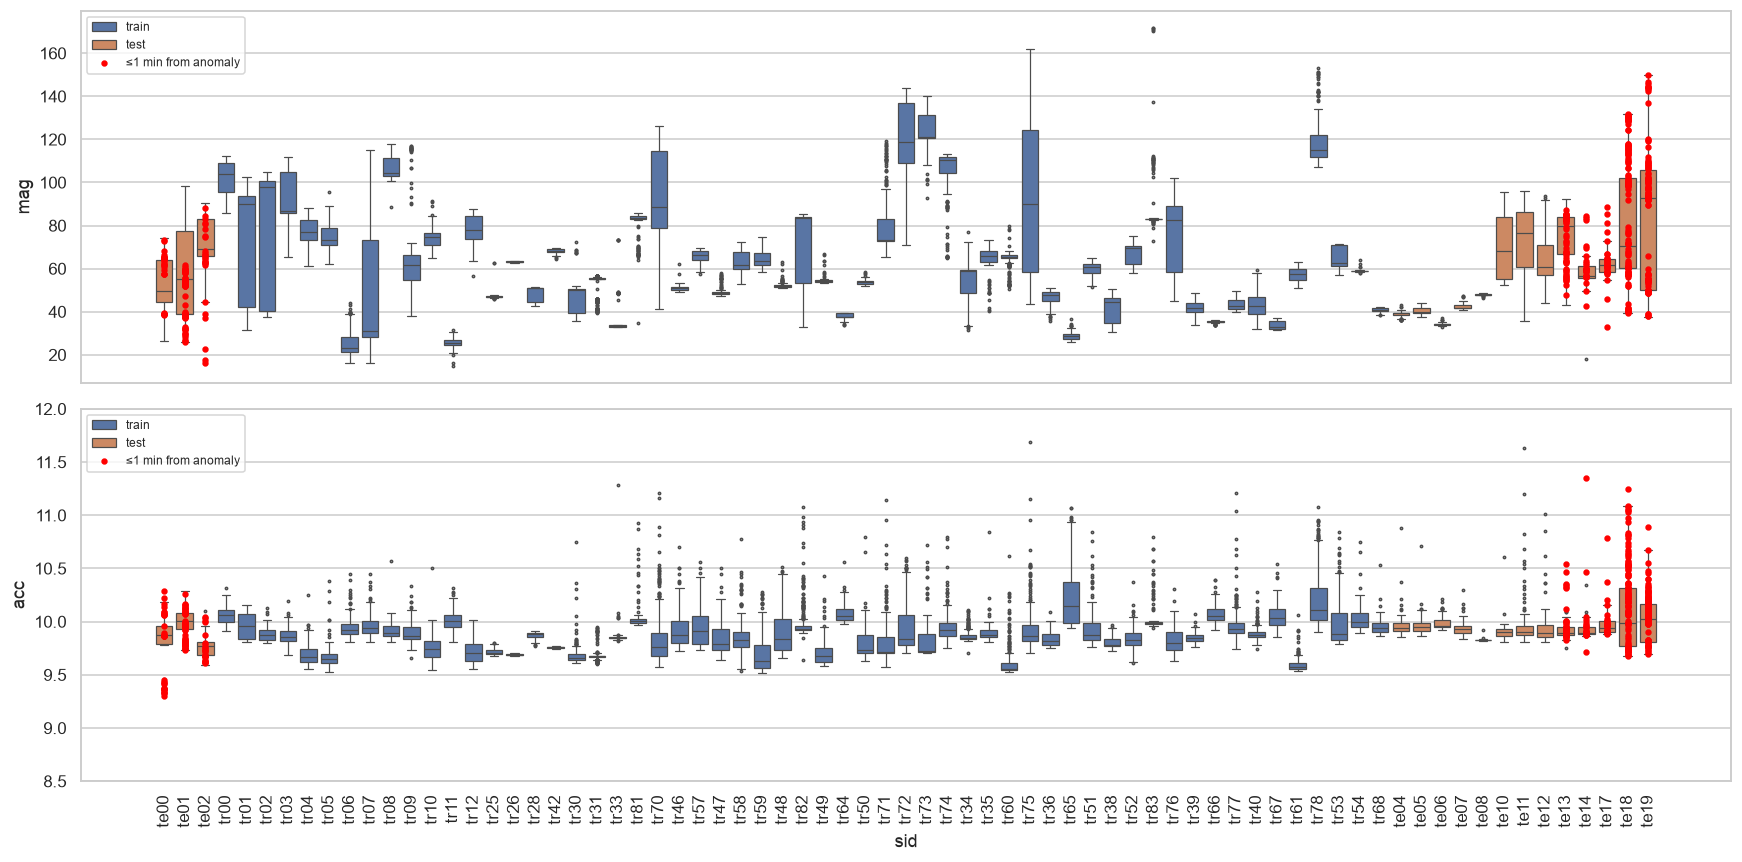

|B|: std of session means = 22.2 µT, median within-session std = 6.0 µT


In [8]:
big = df.groupby(["split", "session"]).filter(lambda g: len(g) >= 30).copy()
big["sid"] = big.split.str[:2] + big.session.astype(str).str.zfill(2)
order = big.groupby("sid").t.min().sort_values().index
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
for ax, c in zip(axes, ["mag", "acc"]):
    sns.boxplot(big, x="sid", y=c, hue="split", order=order, ax=ax, fliersize=1.5, linewidth=0.8, dodge=False)
    hits = big[big.near_anom]
    ax.scatter([list(order).index(s) for s in hits.sid], hits[c], color="red", s=10, zorder=5, label="≤1 min from anomaly")
    ax.legend(loc="upper left", fontsize=8)
axes[1].set_ylim(8.5, 12); axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()
s = big.groupby("sid").mag.agg(["mean", "std"])
print(f"|B|: std of session means = {s['mean'].std():.1f} µT, median within-session std = {s['std'].median():.1f} µT")

## 7. The test set as a time series

Everything in the test file, in file order (x = row number, so gaps are squeezed out). Grey lines separate sessions, red bands are ±1 min around each anomaly timestamp.

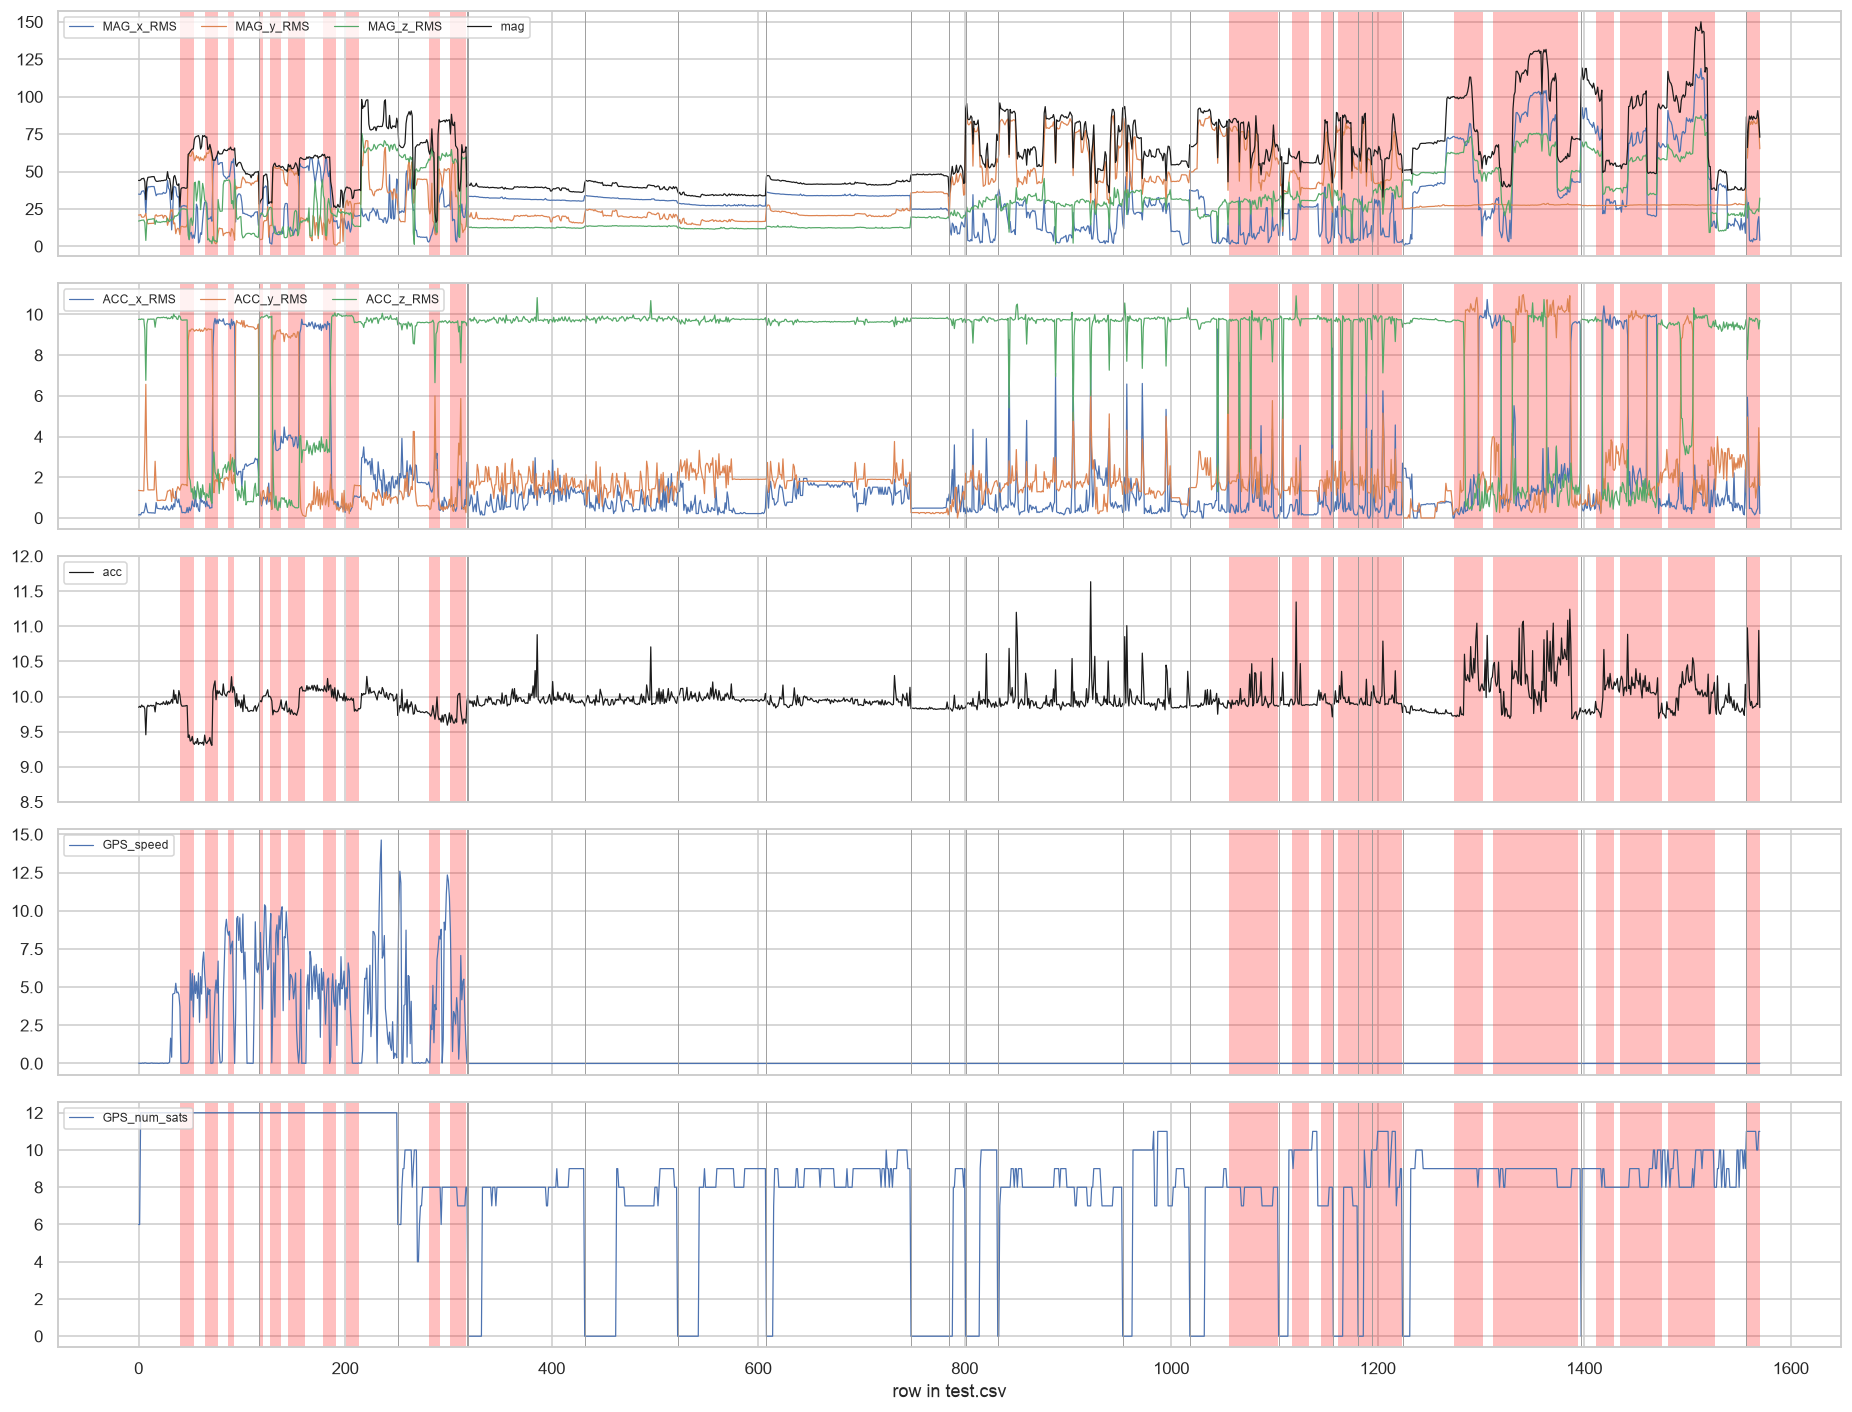

In [9]:
def shade(ax, d):
    for b in d.index[d.session.diff().fillna(0) != 0]:
        ax.axvline(b, color="0.6", lw=0.6)
    for i in d.index[d.near_anom]:
        ax.axvspan(i - 0.5, i + 0.5, color="red", alpha=0.25, lw=0)

d = te.reset_index(drop=True)
panels = [("MAG_x_RMS", "MAG_y_RMS", "MAG_z_RMS", "mag"), ("ACC_x_RMS", "ACC_y_RMS", "ACC_z_RMS"), ("acc",), ("GPS_speed",), ("GPS_num_sats",)]
fig, axes = plt.subplots(len(panels), 1, figsize=(17, 13), sharex=True)
for ax, cols in zip(axes, panels):
    for c in cols:
        ax.plot(d.index, d[c], lw=0.8, label=c, color="k" if c in ("mag", "acc") else None)
    shade(ax, d); ax.legend(loc="upper left", fontsize=8, ncol=4)
axes[2].set_ylim(8.5, 12)
axes[-1].set_xlabel("row in test.csv")
plt.tight_layout(); plt.show()

Same view for the training file, for comparison (no labels).

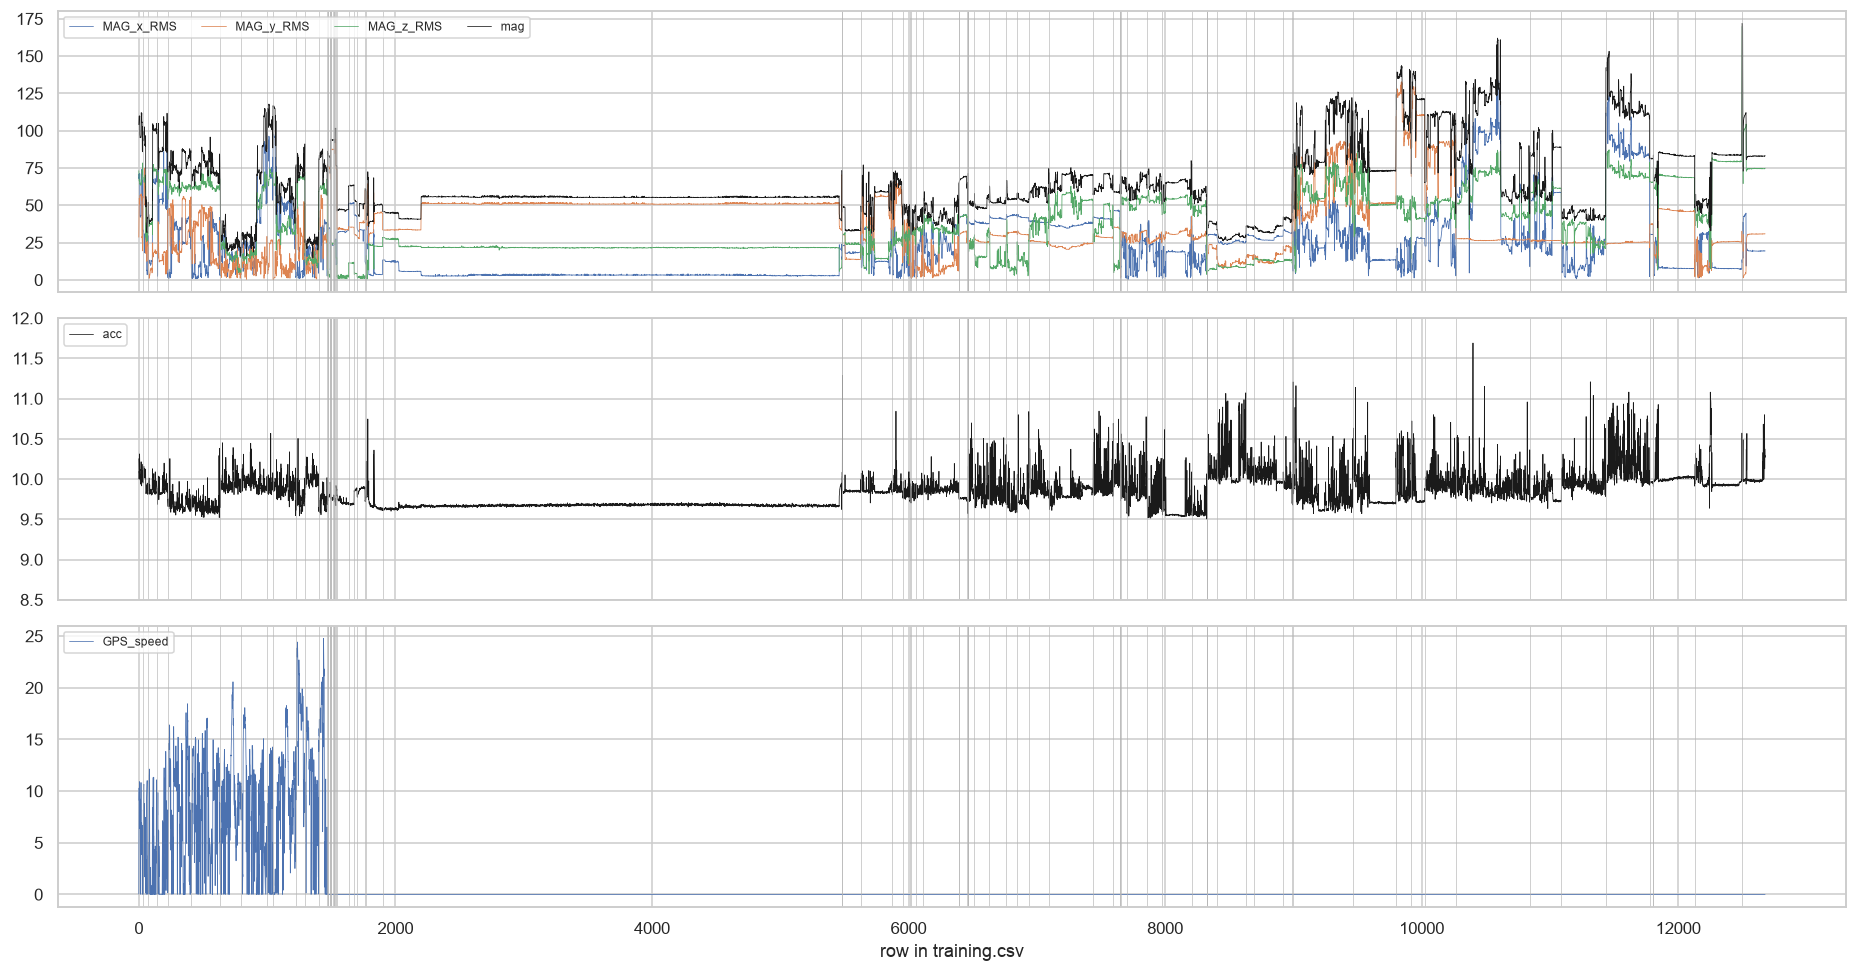

In [10]:
d = tr.reset_index(drop=True)
fig, axes = plt.subplots(3, 1, figsize=(17, 9), sharex=True)
for c in ["MAG_x_RMS", "MAG_y_RMS", "MAG_z_RMS", "mag"]:
    axes[0].plot(d.index, d[c], lw=0.5, label=c, color="k" if c == "mag" else None)
axes[1].plot(d.index, d.acc, lw=0.5, color="k", label="acc"); axes[1].set_ylim(8.5, 12)
axes[2].plot(d.index, d.GPS_speed, lw=0.5, label="GPS_speed")
for ax in axes:
    for b in d.index[d.session.diff().fillna(0) != 0]:
        ax.axvline(b, color="0.7", lw=0.4)
    ax.legend(loc="upper left", fontsize=8, ncol=4)
axes[-1].set_xlabel("row in training.csv")
plt.tight_layout(); plt.show()

## 8. Zoom in on individual anomalies

±10 minutes around a sample of the anomaly timestamps (red line). Left: magnetic field per axis and |B|. Right: acceleration per axis and |a|.

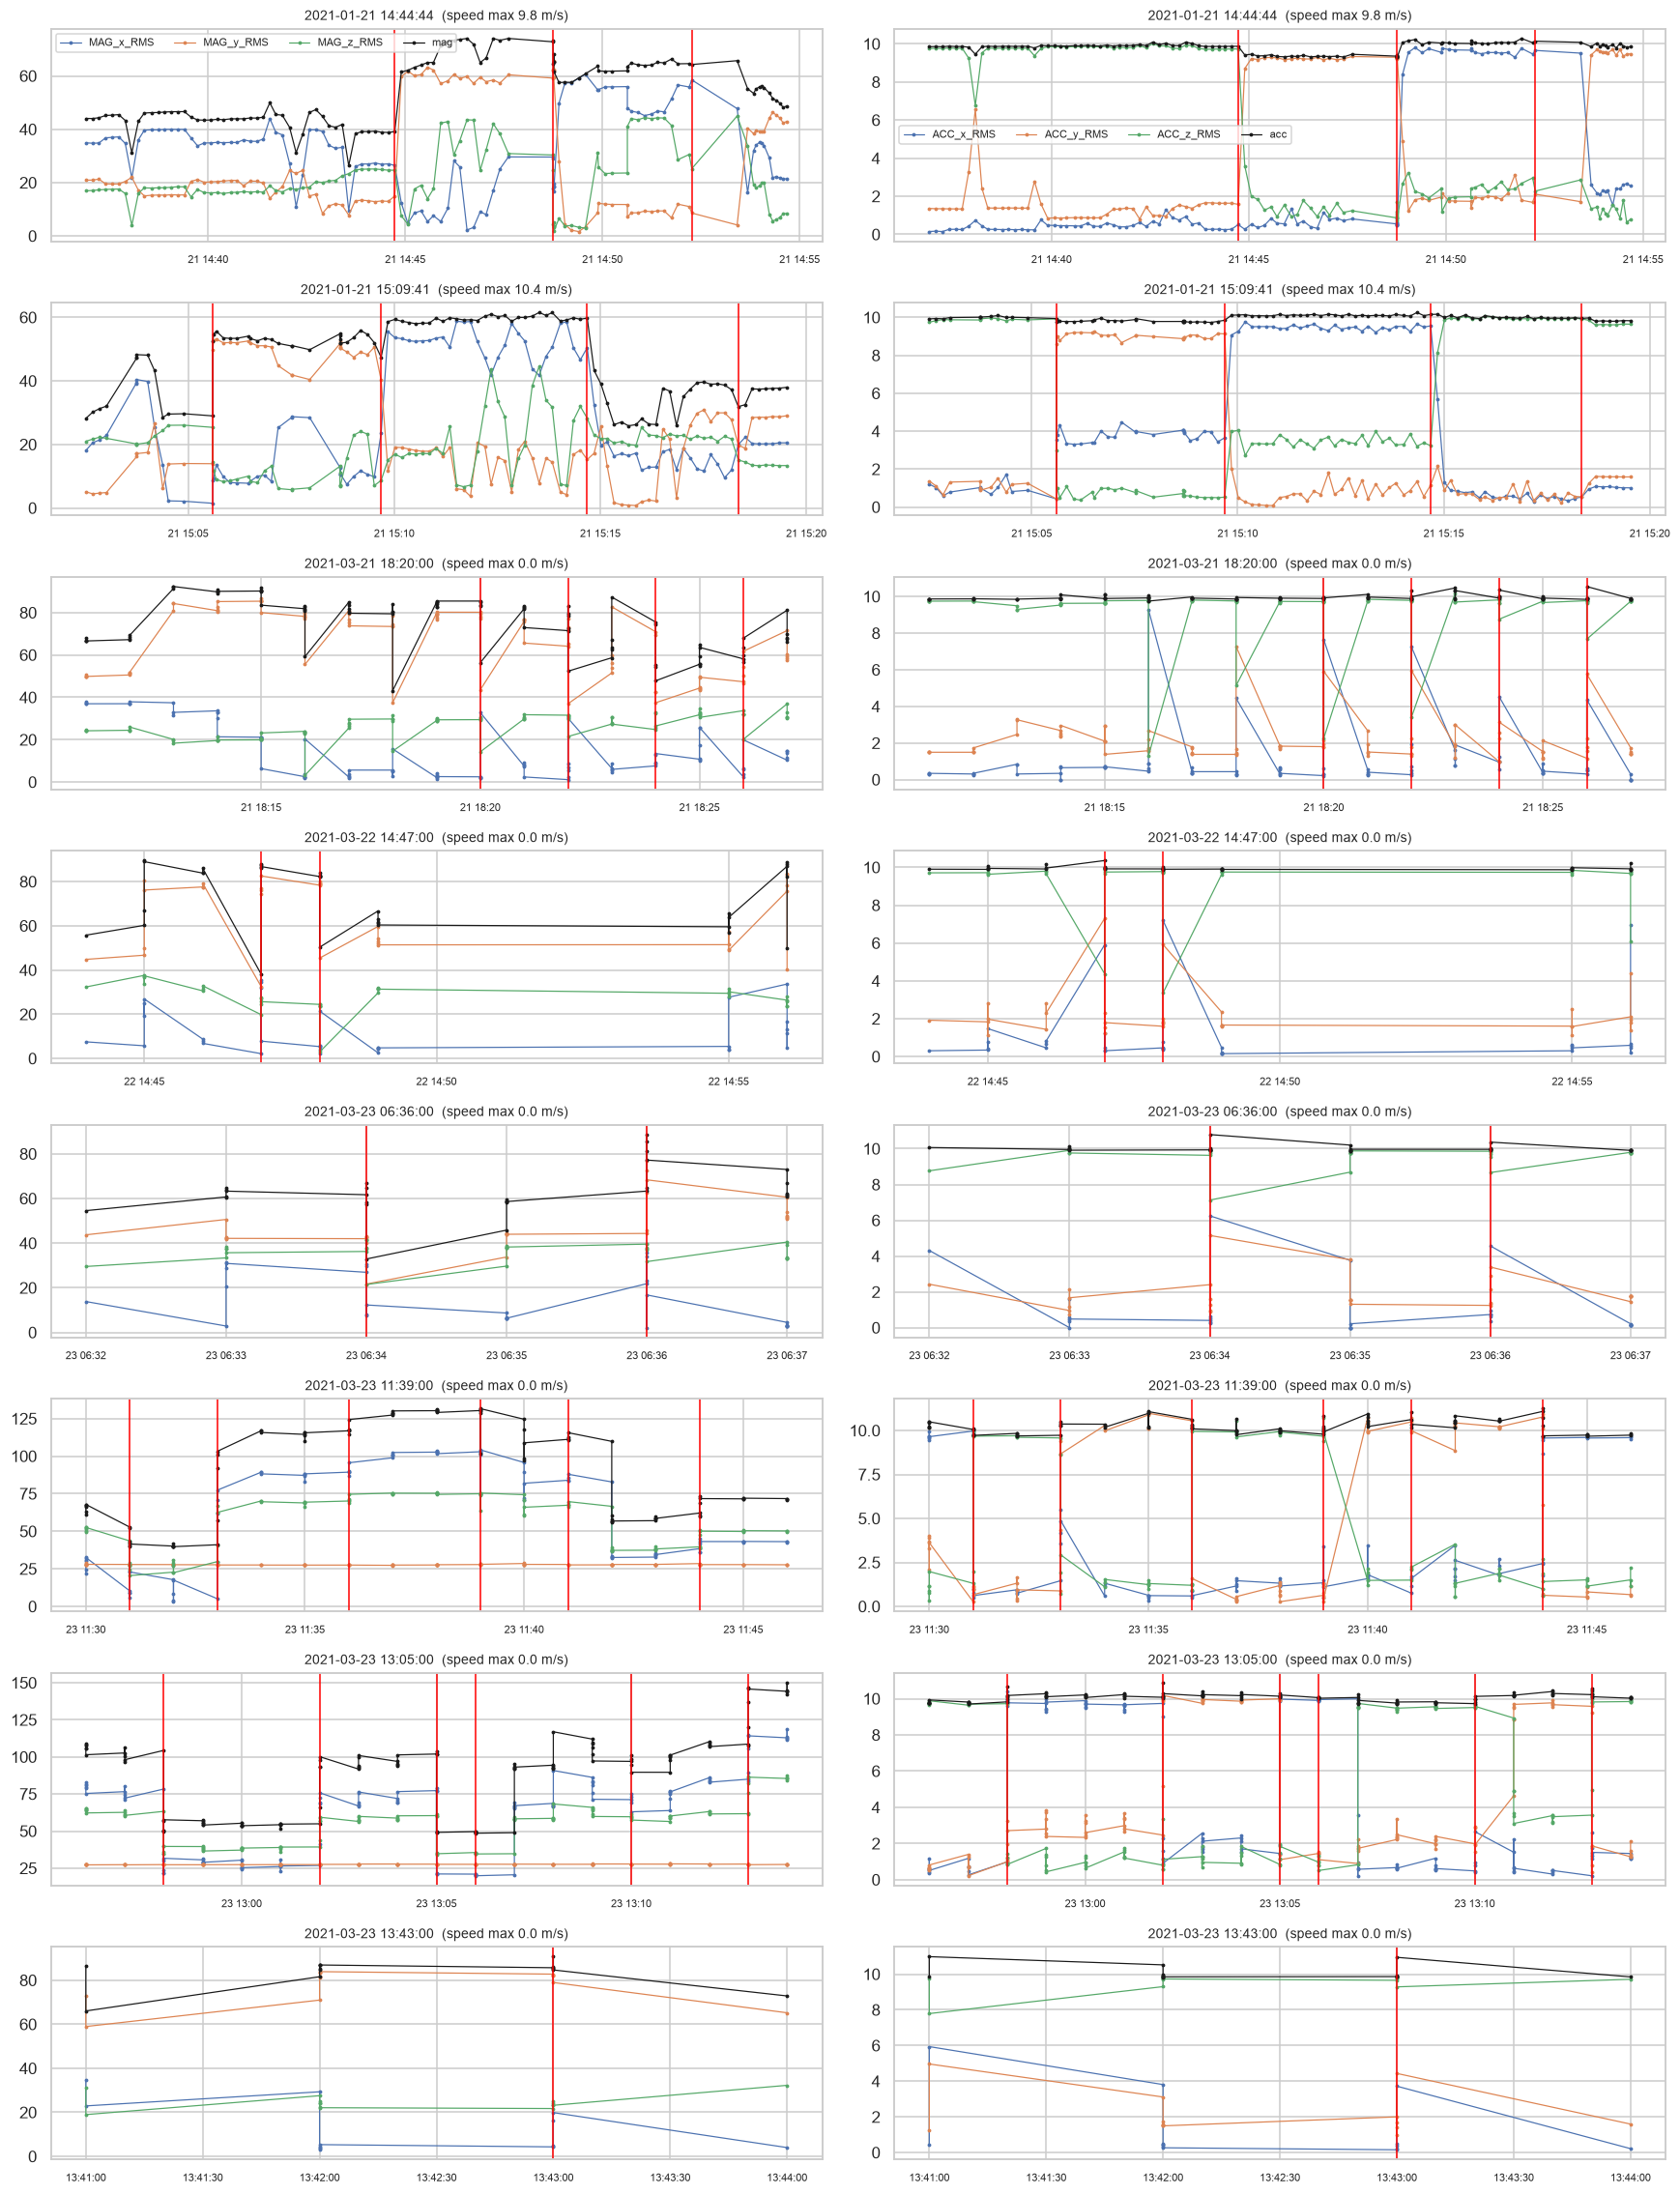

In [11]:
picks = anom.iloc[np.linspace(0, len(anom) - 1, 8).astype(int)]
fig, axes = plt.subplots(len(picks), 2, figsize=(16, 2.6 * len(picks)))
for row, a in zip(axes, picks):
    w = te[(te.t > a - pd.Timedelta("10min")) & (te.t < a + pd.Timedelta("10min"))]
    for ax, cols in zip(row, [["MAG_x_RMS", "MAG_y_RMS", "MAG_z_RMS", "mag"], ["ACC_x_RMS", "ACC_y_RMS", "ACC_z_RMS", "acc"]]):
        for c in cols:
            ax.plot(w.t, w[c], ".-", ms=3, lw=0.8, label=c, color="k" if c in ("mag", "acc") else None)
        for b in anom[(anom > w.t.min()) & (anom < w.t.max())]:
            ax.axvline(b, color="red", lw=1)
        ax.set_title(f"{a}  (speed max {w.GPS_speed.max():.1f} m/s)", fontsize=9)
        ax.tick_params(axis="x", labelsize=7)
axes[0][0].legend(fontsize=7, ncol=4); axes[0][1].legend(fontsize=7, ncol=4)
plt.tight_layout(); plt.show()

## 8b. Which axis carries gravity

When the box lies still, gravity (~9.8 m/s²) sits almost entirely on one axis. The axis with the largest ACC RMS therefore tells how the box is lying. A change of that axis means the box was turned over.

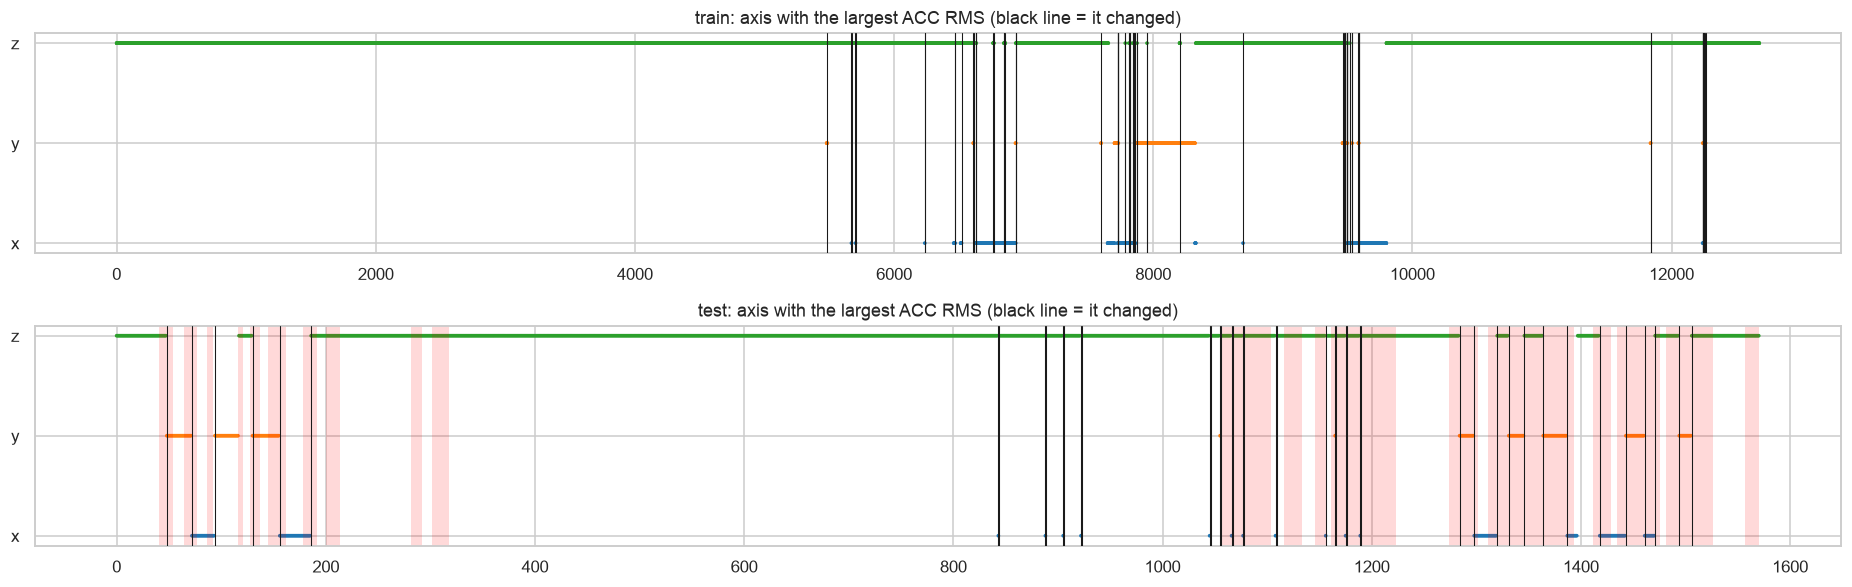

gravity-axis changes: train 77, test 44
anomaly timestamps with a gravity-axis change within ±1 min: 26 of 39
test gravity-axis changes within ±1 min of an anomaly: 30 of 44
share of rows per gravity axis:
        train   test
g_axis              
x       0.062  0.083
y       0.042  0.100
z       0.895  0.817


In [12]:
for d in (tr, te):
    d["g_axis"] = d[["ACC_x_RMS", "ACC_y_RMS", "ACC_z_RMS"]].to_numpy().argmax(1)
    d["flip"] = d.groupby("session").g_axis.diff().fillna(0).ne(0)
fig, axes = plt.subplots(2, 1, figsize=(17, 5.5))
for ax, (name, d) in zip(axes, [("train", tr), ("test", te)]):
    d = d.reset_index(drop=True)
    ax.scatter(d.index, d.g_axis, s=2, c=d.g_axis, cmap="tab10", vmin=0, vmax=9)
    if name == "test":
        for i in d.index[d.near_anom]:
            ax.axvspan(i - 0.5, i + 0.5, color="red", alpha=0.15, lw=0)
    for i in d.index[d.flip]:
        ax.axvline(i, color="k", lw=0.7, zorder=3)
    ax.set_yticks([0, 1, 2], ["x", "y", "z"]); ax.set_title(f"{name}: axis with the largest ACC RMS (black line = it changed)")
plt.tight_layout(); plt.show()
fl = te[te.flip]
hit = [(abs(fl.t - a) <= TOL).any() for a in anom]
print(f"gravity-axis changes: train {tr.flip.sum()}, test {te.flip.sum()}")
print(f"anomaly timestamps with a gravity-axis change within ±1 min: {sum(hit)} of {len(anom)}")
print(f"test gravity-axis changes within ±1 min of an anomaly: {fl.near_anom.sum()} of {len(fl)}")
print("share of rows per gravity axis:"); print(pd.DataFrame({n: d.g_axis.map({0:'x',1:'y',2:'z'}).value_counts(normalize=True).round(3) for n, d in [('train', tr), ('test', te)]}))

## 9. Row-to-row changes

Anomalies may show up as jumps rather than unusual levels. Δ = change from the previous row inside the same session.

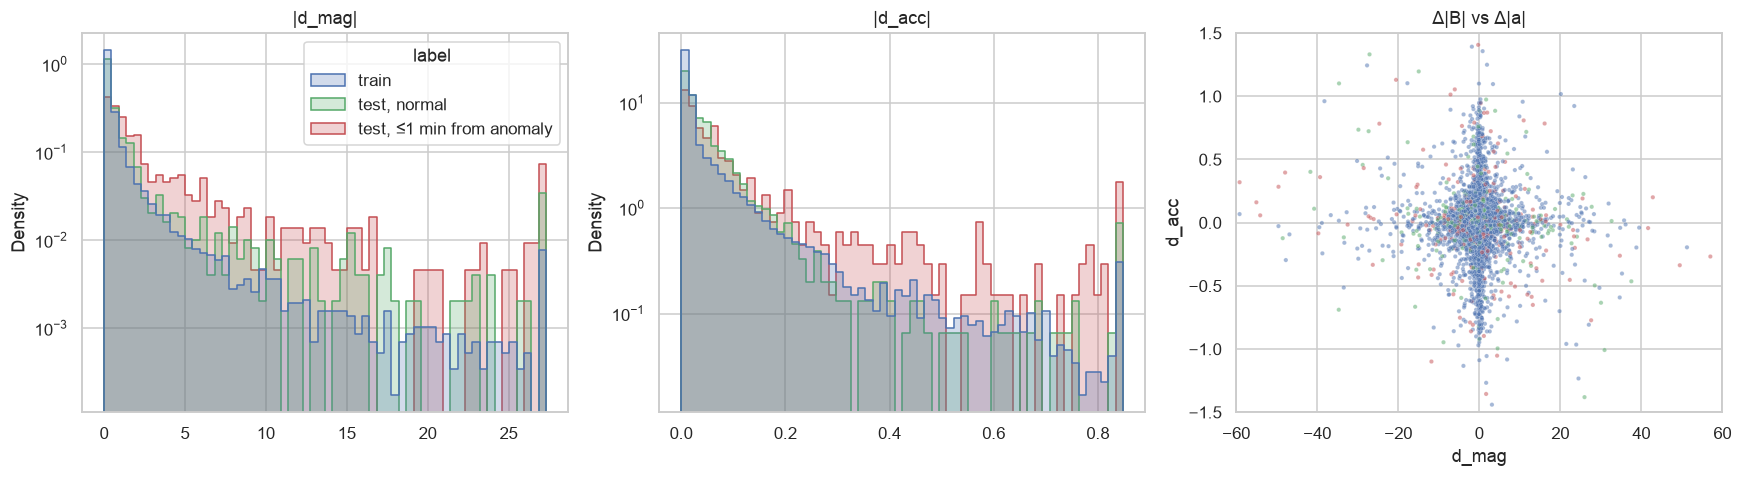

In [13]:
for d in (tr, te):
    for c in ["mag", "acc"] + IMU:
        d["d_" + c] = d.groupby("session")[c].diff()
dd = pd.concat([tr, te], ignore_index=True)
dd["label"] = df["label"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, ["d_mag", "d_acc"]):
    sns.histplot(dd, x=dd[c].abs().clip(upper=dd[c].abs().quantile(0.995)), hue="label", palette=PAL, bins=60,
                 stat="density", common_norm=False, element="step", ax=ax, legend=ax is axes[0])
    ax.set_yscale("log"); ax.set_title(f"|{c}|"); ax.set_xlabel("")
sns.scatterplot(dd.sample(frac=1, random_state=0), x="d_mag", y="d_acc", hue="label", palette=PAL, s=8, alpha=0.5, ax=axes[2], legend=False)
axes[2].set_xlim(-60, 60); axes[2].set_ylim(-1.5, 1.5); axes[2].set_title("Δ|B| vs Δ|a|")
plt.tight_layout(); plt.show()

## 10. Physics check while driving

In January the GPS gives speed every ~10 s, so dv/dt is a (coarse) longitudinal acceleration. The IMU part that is not gravity is roughly √(|a|² − g²).

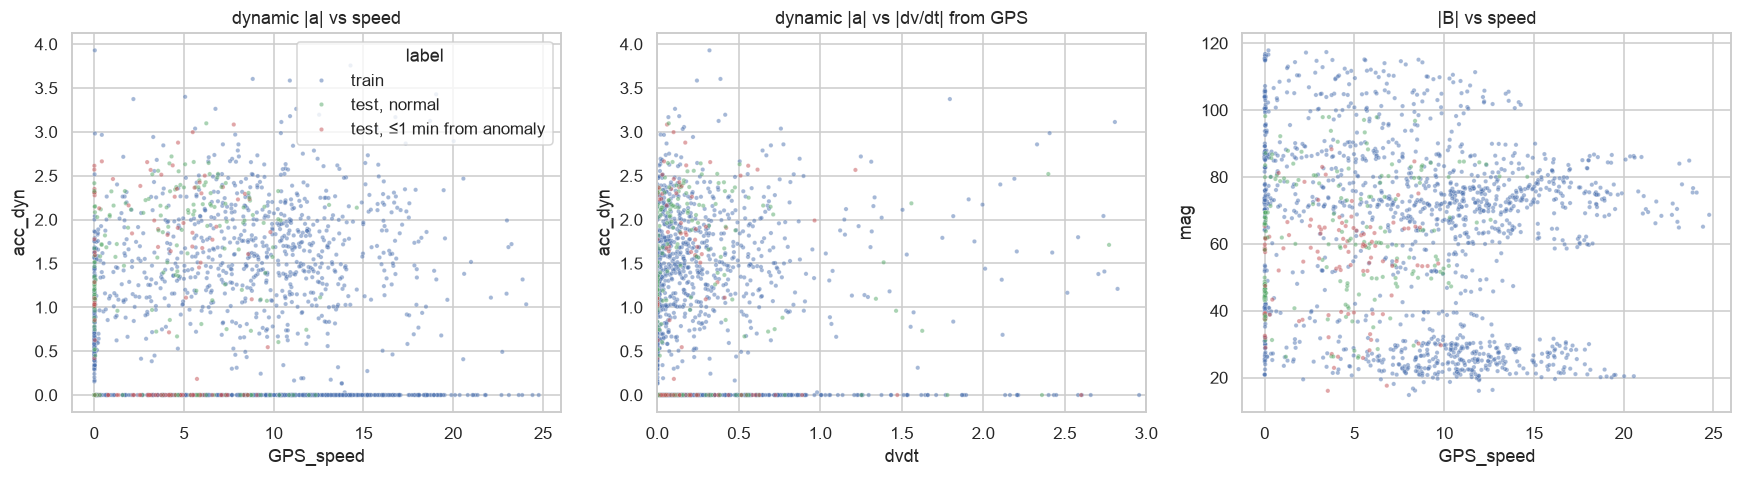

In [14]:
j = df[(df.t < "2021-03-01") & ~df.no_fix].copy()
j["dvdt"] = j.groupby(["split", "session"]).GPS_speed.diff() / j.dt
j["acc_dyn"] = np.sqrt(np.clip(j.acc**2 - G**2, 0, None))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.scatterplot(j, x="GPS_speed", y="acc_dyn", hue="label", palette=PAL, s=8, alpha=0.5, ax=axes[0])
axes[0].set_title("dynamic |a| vs speed")
sns.scatterplot(j, x=j.dvdt.abs(), y="acc_dyn", hue="label", palette=PAL, s=8, alpha=0.5, ax=axes[1], legend=False)
axes[1].set_xlim(0, 3); axes[1].set_title("dynamic |a| vs |dv/dt| from GPS")
sns.scatterplot(j, x="GPS_speed", y="mag", hue="label", palette=PAL, s=8, alpha=0.5, ax=axes[2], legend=False)
axes[2].set_title("|B| vs speed")
plt.tight_layout(); plt.show()

## 11. Correlations between IMU columns

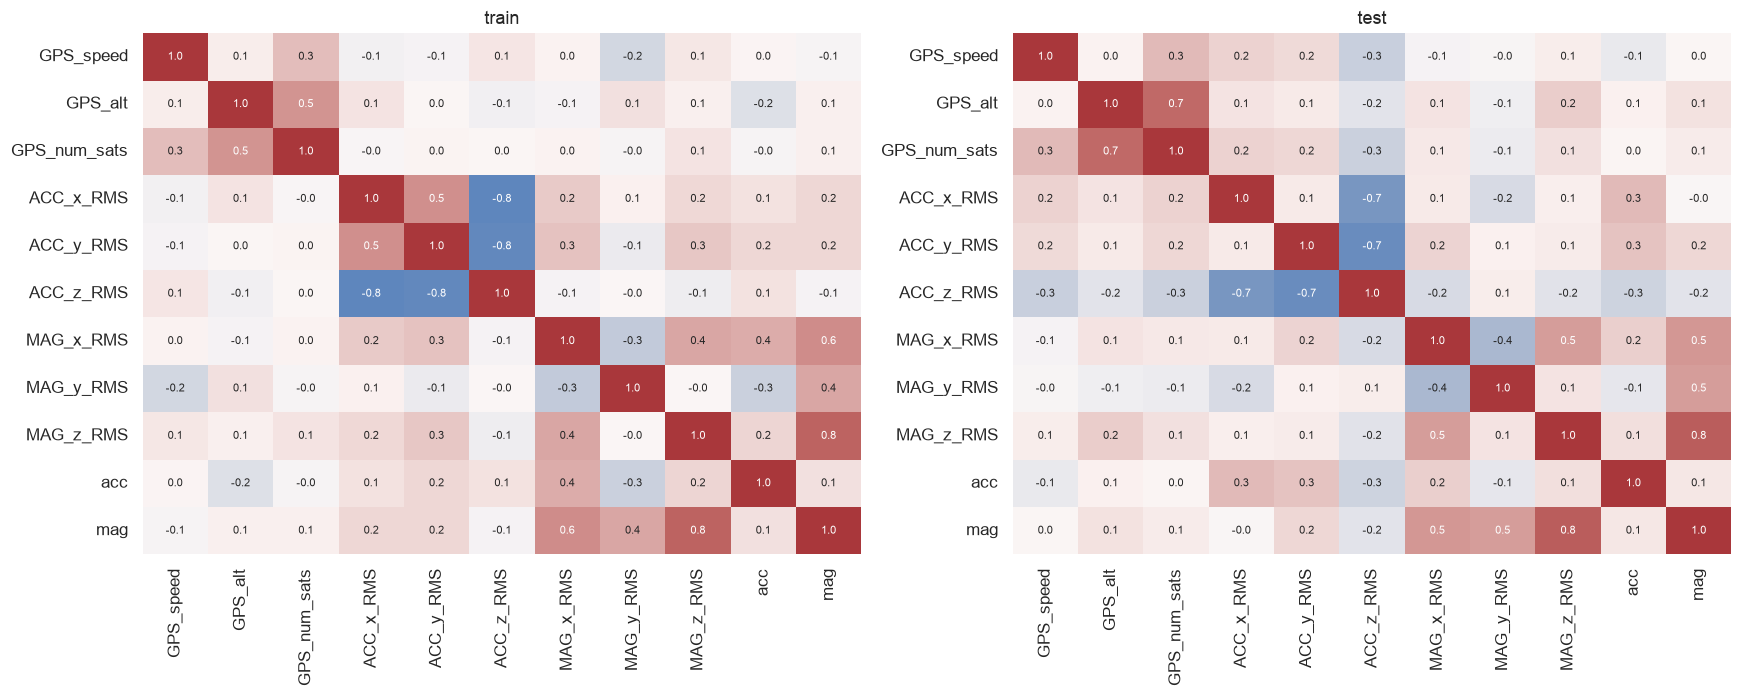

In [15]:
cc = ["GPS_speed", "GPS_alt", "GPS_num_sats"] + IMU + ["acc", "mag"]
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (name, d) in zip(axes, [("train", tr), ("test", te)]):
    sns.heatmap(d[cc].corr(), vmin=-1, vmax=1, cmap="vlag", annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax, cbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 12. All IMU features in 2-D (PCA)

PCA fitted on the standardised training IMU columns, then the test rows projected into the same space. Anomalies that fall outside the training cloud are easy for any density/distance method; ones that fall inside are not.

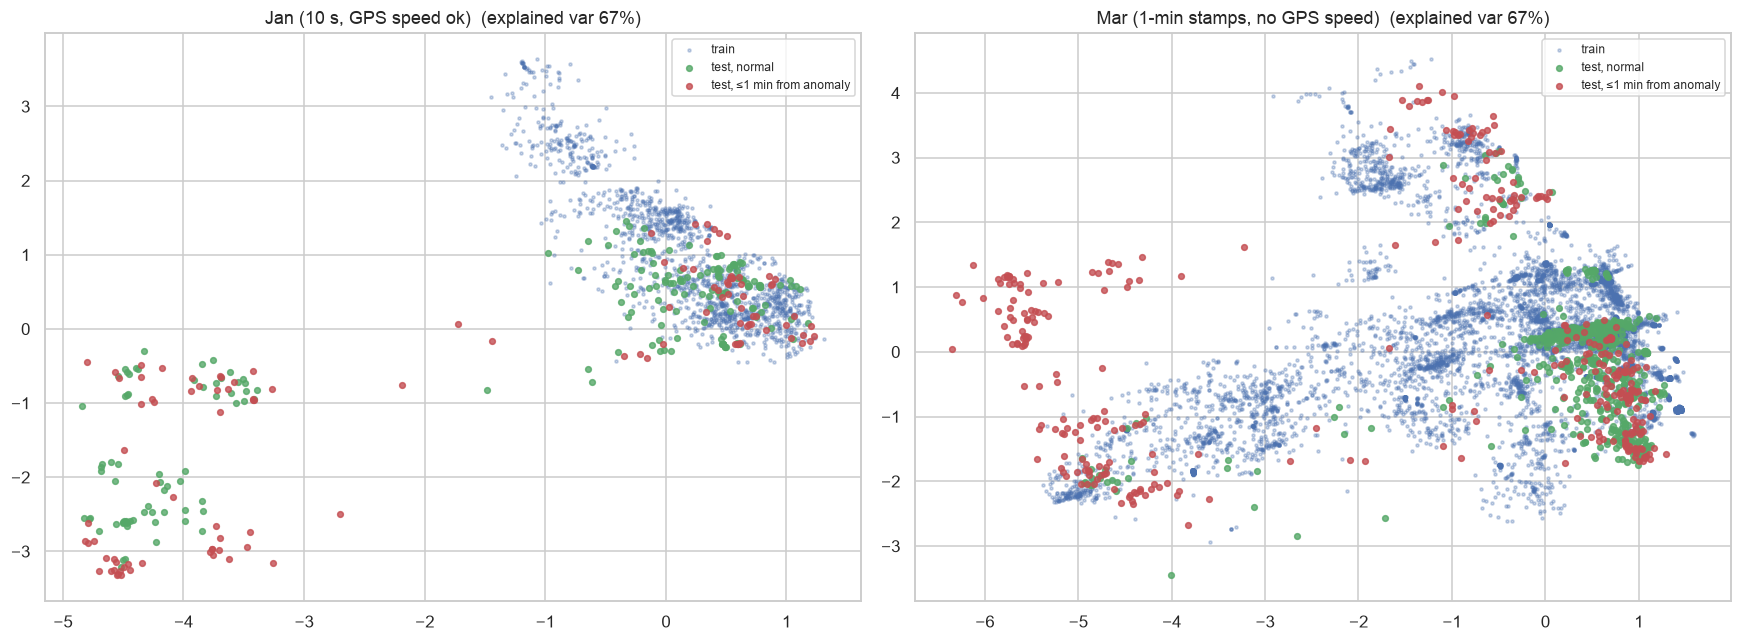

In [16]:
sc = StandardScaler().fit(tr[IMU]); pca = PCA(2).fit(sc.transform(tr[IMU]))
P = pd.DataFrame(pca.transform(sc.transform(df[IMU])), columns=["PC1", "PC2"]); P["label"] = df.label; P["regime"] = df.regime
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (reg, g) in zip(axes, P.groupby("regime")):
    for lab in PAL:
        h = g[g.label == lab]
        ax.scatter(h.PC1, h.PC2, s=4 if lab == "train" else 14, alpha=0.3 if lab == "train" else 0.8, color=PAL[lab], label=lab)
    ax.set_title(f"{reg}  (explained var {pca.explained_variance_ratio_.sum():.0%})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 13. The anomalies themselves

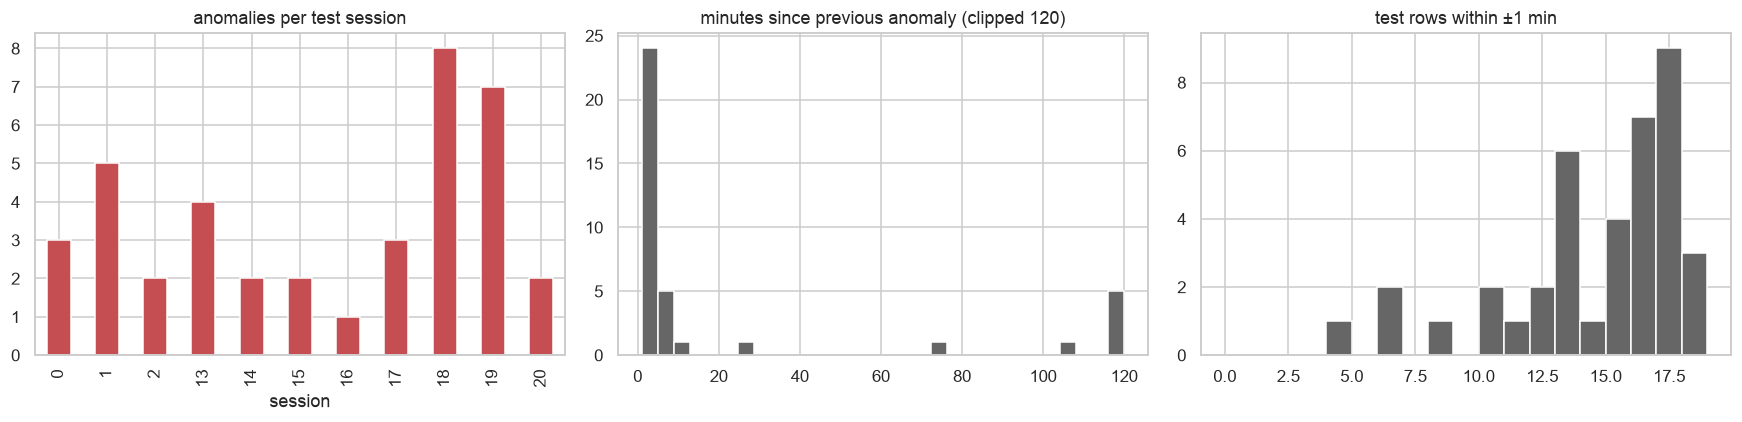

test rows within ±1 min of an anomaly: 479 of 1571 (30.5%)
anomalies while moving (speed > 1 m/s): 5 of 39


,t,rows_within_1min,gap_to_prev_min,session,speed
0,2021-01-21 14:44:44,13,NaN,0,0.020062
1,2021-01-21 14:48:45,12,4.016667,0,4.859022
2,2021-01-21 14:52:16,6,3.516667,0,3.146585
3,2021-01-21 15:02:31,4,10.250000,1,5.842555
4,2021-01-21 15:05:36,10,3.083333,1,0.044238
5,2021-01-21 15:09:41,17,4.083333,1,0.027778
6,2021-01-21 15:14:41,13,5.000000,1,0.009774
7,2021-01-21 15:18:21,13,3.666667,1,0.030864
8,2021-01-21 17:05:24,10,107.050000,2,3.864173
9,2021-01-21 17:10:29,16,5.083333,2,7.074029


In [17]:
ev = pd.DataFrame({"t": anom})
ev["rows_within_1min"] = [(abs(te.t - a) <= TOL).sum() for a in anom]
ev["gap_to_prev_min"] = ev.t.diff().dt.total_seconds() / 60
ev["session"] = [te.session[(te.t - a).abs().idxmin()] for a in anom]
ev["speed"] = [te.GPS_speed[(te.t - a).abs().idxmin()] for a in anom]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ev.groupby("session").size().plot.bar(ax=axes[0], color=PAL["test, ≤1 min from anomaly"]); axes[0].set_title("anomalies per test session")
axes[1].hist(ev.gap_to_prev_min.dropna().clip(upper=120), bins=30, color="0.4"); axes[1].set_title("minutes since previous anomaly (clipped 120)")
axes[2].hist(ev.rows_within_1min, bins=range(0, ev.rows_within_1min.max() + 2), color="0.4"); axes[2].set_title("test rows within ±1 min")
plt.tight_layout(); plt.show()
print(f"test rows within ±1 min of an anomaly: {te.near_anom.sum()} of {len(te)} ({te.near_anom.mean():.1%})")
print(f"anomalies while moving (speed > 1 m/s): {(ev.speed > 1).sum()} of {len(ev)}")
ev

## What stands out (facts from the plots above)

- **Timestamps:** three formats across the files, March stamps cut to whole minutes, `training.csv` not in time order. Parse them before anything else.
- **March has no GPS speed** (always 0 while the position moves), so speed-based physics checks only work on the January part.
- **Missing GPS:** 924 train / 190 test rows have lat = lon = 0; the original loader drops those rows.
- **|B| level depends on the session** (section 6): the session means differ much more than the spread inside a session.
- **Anomalies line up with the box being turned over** (sections 7, 8, 8b): at most anomaly timestamps the gravity axis switches and the magnetic components jump together. The training file contains such switches too, so "orientation changed" alone is not the whole story.
- **Labels are coarse:** an anomaly is a single timestamp; with ±1 min tolerance about 30 % of test rows sit near one.